<a href="https://colab.research.google.com/github/sadhyasora-bit/Fraud-Detection_Model/blob/main/notebook/02_Data_Cleaning_and_Splitting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02. Data Preprocessing

Notebook ini bertujuan mempersiapkan dataset Credit Card Fraud Detection
sebelum digunakan dalam eksperimen.

Tahapan preprocessing meliputi:
1. Dataset loading
2. Data quality checking
3. Duplicate handling
4. Feature and target separation
5. Train-validation-test splitting
6. Data validation
7. Saving preprocessed datasets

## 1. Import library

In [ ]:
# Data manipulation
import os
import json
import shutil
import zipfile
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dataset splitting
from sklearn.model_selection import train_test_split

# Display
from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Library berhasil diimpor!")

Library berhasil diimpor!


## 2. Load dataset

In [ ]:
!pip install -q kagglehub

import kagglehub

# Download dataset
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

# Load CSV
dataset_path = os.path.join(path, "creditcard.csv")

df = pd.read_csv(dataset_path)

print("Dataset berhasil dimuat!")
print("Lokasi:", dataset_path)
print("Ukuran dataset:", df.shape)

display(df.head())

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset berhasil dimuat!
Lokasi: /kaggle/input/creditcardfraud/creditcard.csv
Ukuran dataset: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Pemeriksaan struktur dataset

In [ ]:
print("===== DATASET INFORMATION =====")

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset info:")
df.info()

===== DATASET INFORMATION =====

Shape:
(284807, 31)

Columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column

## 4. Pemeriksaan kualitas data

In [ ]:
# Missing values
missing_values = df.isnull().sum()

# Duplicate rows
duplicate_count = df.duplicated().sum()

# Infinite values
numeric_df = df.select_dtypes(include=np.number)
infinite_count = np.isinf(numeric_df).sum().sum()

print("===== DATA QUALITY CHECK =====")

print("\nMissing Values:")
print("Total missing values:", missing_values.sum())

print("\nDuplicate Rows:")
print("Total duplicates:", duplicate_count)

print("\nInfinite Values:")
print("Total infinite values:", infinite_count)

print("\nMissing values per column:")
display(missing_values[missing_values > 0])

===== DATA QUALITY CHECK =====

Missing Values:
Total missing values: 0

Duplicate Rows:
Total duplicates: 1081

Infinite Values:
Total infinite values: 0

Missing values per column:


,0


## 5. Pemeriksaan distribusi kelas sebelum cleaning

In [ ]:
class_distribution_before = df["Class"].value_counts().sort_index()

class_percentage_before = (
    df["Class"].value_counts(normalize=True).sort_index() * 100
)

distribution_before = pd.DataFrame({
    "Count": class_distribution_before,
    "Percentage": class_percentage_before
})

distribution_before.index = ["Non-Fraud", "Fraud"]

display(distribution_before)

print("\nTotal records:", len(df))

,Count,Percentage
Non-Fraud,284315,99.827251
Fraud,492,0.172749



Total records: 284807


## 6. Duplicate handling

In [ ]:
# Salin dataset
df_clean = df.copy()

# Jumlah duplikasi sebelum dihapus
duplicates_before = df_clean.duplicated().sum()

# Hapus baris duplikat
df_clean = df_clean.drop_duplicates().copy()

# Reset index
df_clean = df_clean.reset_index(drop=True)

print("===== DUPLICATE HANDLING =====")
print("Duplicates removed:", duplicates_before)
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

===== DUPLICATE HANDLING =====
Duplicates removed: 1081
Original shape: (284807, 31)
Cleaned shape: (283726, 31)
Remaining duplicates: 0


## 7. Pemeriksaan konsistensi label

In [ ]:
feature_columns = [
    col for col in df_clean.columns
    if col != "Class"
]

label_conflicts = (
    df_clean.groupby(feature_columns, dropna=False)["Class"]
    .nunique()
)

conflict_count = (label_conflicts > 1).sum()

print("===== LABEL CONSISTENCY CHECK =====")
print("Feature combinations with conflicting labels:", conflict_count)

if conflict_count == 0:
    print("No conflicting labels found.")
else:
    print("Warning: Conflicting labels detected.")

===== LABEL CONSISTENCY CHECK =====
Feature combinations with conflicting labels: 0
No conflicting labels found.


## 8. Pemeriksaan dataset setelah cleaning

In [ ]:
print("===== CLEANED DATASET =====")

print("\nShape:")
print(df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nClass Distribution:")
print(df_clean["Class"].value_counts().sort_index())

print("\nClass Percentage:")
print(
    (df_clean["Class"].value_counts(normalize=True).sort_index() * 100)
    .round(6)
)

===== CLEANED DATASET =====

Shape:
(283726, 31)

Missing Values:
0

Duplicate Rows:
0

Class Distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Class Percentage:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


## 9. Feature-target separation

In [ ]:
# Features
X = df_clean.drop(columns=["Class"])

# Target
y = df_clean["Class"].astype(int)

print("===== FEATURE-TARGET SEPARATION =====")

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts().sort_index())

===== FEATURE-TARGET SEPARATION =====
X shape: (283726, 30)
y shape: (283726,)

Feature columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

Target distribution:
Class
0    283253
1       473
Name: count, dtype: int64


## 10. Stratified train-validation-test split

In [ ]:
# Split 1: 70% training dan 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Split 2: temporary dibagi menjadi validation dan testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("===== DATA SPLITTING COMPLETED =====")

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)

===== DATA SPLITTING COMPLETED =====
X_train: (198608, 30)
X_val  : (42559, 30)
X_test : (42559, 30)

y_train: (198608,)
y_val  : (42559,)
y_test : (42559,)


## 11. Validasi proporsi data split

In [ ]:
total_records = len(df_clean)

split_summary = pd.DataFrame({
    "Subset": ["Training", "Validation", "Testing"],
    "Records": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Percentage": [
        len(X_train) / total_records * 100,
        len(X_val) / total_records * 100,
        len(X_test) / total_records * 100
    ]
})

display(split_summary.round(2))

print("Total records after splitting:",
      len(X_train) + len(X_val) + len(X_test))

print("Original cleaned records:", total_records)

,Subset,Records,Percentage
0,Training,198608,70.0
1,Validation,42559,15.0
2,Testing,42559,15.0


Total records after splitting: 283726
Original cleaned records: 283726


## 12. Validasi distribusi kelas

In [ ]:
class_distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Testing": y_test.value_counts()
}).fillna(0).astype(int)

class_distribution.loc["Total"] = class_distribution.sum()

print("===== CLASS DISTRIBUTION =====")
display(class_distribution)

===== CLASS DISTRIBUTION =====


,Training,Validation,Testing
Class,,,
0,198277,42488,42488
1,331,71,71
Total,198608,42559,42559


## 13. Visualisasi distribusi kelas


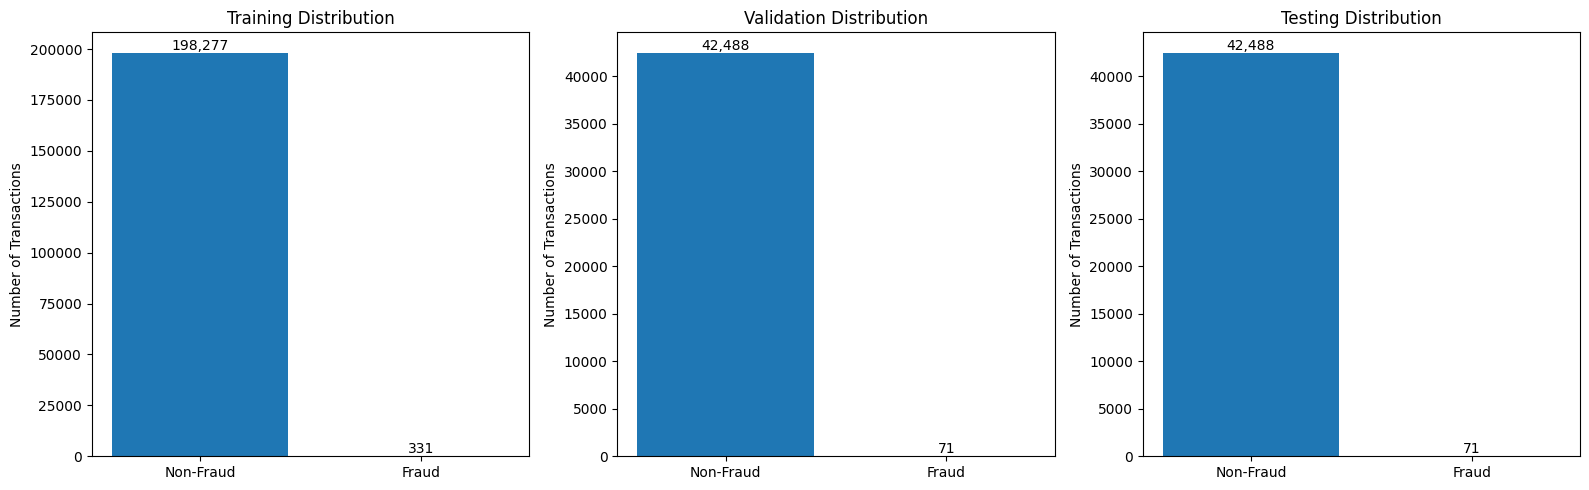

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

datasets = [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]

for ax, (name, target) in zip(axes, datasets):

    counts = target.value_counts().reindex([0, 1], fill_value=0)

    bars = ax.bar(
        ["Non-Fraud", "Fraud"],
        counts.values
    )

    ax.set_title(f"{name} Distribution")
    ax.set_ylabel("Number of Transactions")

    for bar, value in zip(bars, counts.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:,}",
            ha="center",
            va="bottom"
        )

plt.tight_layout()
plt.show()

## 14. Pemeriksaan missing, infinite, dan tipe data

In [ ]:
def validate_dataset(X_data, y_data, name):

    print(f"\n===== {name} =====")

    print("Missing values:", X_data.isnull().sum().sum())
    print("Infinite values:", np.isinf(X_data.select_dtypes(include=np.number)).sum().sum())
    print("Non-numeric columns:",
          X_data.select_dtypes(exclude=np.number).columns.tolist())

    print("X shape:", X_data.shape)
    print("y shape:", y_data.shape)

    assert X_data.isnull().sum().sum() == 0
    assert np.isfinite(X_data.to_numpy()).all()
    assert X_data.select_dtypes(exclude=np.number).empty
    assert len(X_data) == len(y_data)
    assert list(X_data.columns) == feature_columns

    print("Validation passed.")

validate_dataset(X_train, y_train, "TRAINING")
validate_dataset(X_val, y_val, "VALIDATION")
validate_dataset(X_test, y_test, "TESTING")


===== TRAINING =====
Missing values: 0
Infinite values: 0
Non-numeric columns: []
X shape: (198608, 30)
y shape: (198608,)
Validation passed.

===== VALIDATION =====
Missing values: 0
Infinite values: 0
Non-numeric columns: []
X shape: (42559, 30)
y shape: (42559,)
Validation passed.

===== TESTING =====
Missing values: 0
Infinite values: 0
Non-numeric columns: []
X shape: (42559, 30)
y shape: (42559,)
Validation passed.


## 15. Pemeriksaan overlap antar-subset

In [ ]:
train_indices = set(X_train.index)
val_indices = set(X_val.index)
test_indices = set(X_test.index)

train_val_overlap = train_indices.intersection(val_indices)
train_test_overlap = train_indices.intersection(test_indices)
val_test_overlap = val_indices.intersection(test_indices)

print("===== OVERLAP CHECK =====")

print("Train-Validation overlap:", len(train_val_overlap))
print("Train-Testing overlap:", len(train_test_overlap))
print("Validation-Testing overlap:", len(val_test_overlap))

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("\nNo overlap detected.")

===== OVERLAP CHECK =====
Train-Validation overlap: 0
Train-Testing overlap: 0
Validation-Testing overlap: 0

No overlap detected.


## 16. Menyimpan dataset hasil preprocessing

In [ ]:
output_dir = "/content/preprocessed_data"

os.makedirs(output_dir, exist_ok=True)

# Simpan feature datasets
X_train.to_csv(
    f"{output_dir}/X_train.csv", index=False
)

X_val.to_csv(
    f"{output_dir}/X_val.csv", index=False
)

X_test.to_csv(
    f"{output_dir}/X_test.csv", index=False
)

# Simpan target datasets
y_train.to_csv(
    f"{output_dir}/y_train.csv", index=False
)

y_val.to_csv(
    f"{output_dir}/y_val.csv", index=False
)

y_test.to_csv(
    f"{output_dir}/y_test.csv", index=False
)

# Simpan indeks asli untuk audit pembagian data
split_indices = pd.DataFrame({
    "original_index": (
        list(X_train.index) +
        list(X_val.index) +
        list(X_test.index)
    ),
    "subset": (
        ["train"] * len(X_train) +
        ["validation"] * len(X_val) +
        ["test"] * len(X_test)
    )
})

split_indices.to_csv(
    f"{output_dir}/split_indices.csv",
    index=False
)

print("All preprocessed datasets saved successfully!")
print("Output directory:", output_dir)

All preprocessed datasets saved successfully!
Output directory: /content/preprocessed_data


## 17. Menyimpan metadata preprocessing

In [ ]:
metadata = {
    "dataset": "European Credit Card Fraud Detection",
    "source": "Kaggle - mlg-ulb/creditcardfraud",
    "random_state": RANDOM_STATE,
    "split_ratio": {
        "training": 0.70,
        "validation": 0.15,
        "testing": 0.15
    },
    "preprocessing": {
        "duplicate_removal": True,
        "duplicates_removed": int(duplicates_before),
        "missing_value_handling": "No missing values detected",
        "feature_target_separation": True,
        "scaling": "Not applied in this notebook",
        "class_imbalance_handling": "Not applied in this notebook"
    },
    "dataset_shape": {
        "cleaned_total": int(len(df_clean)),
        "features": int(X.shape[1]),
        "training": int(len(X_train)),
        "validation": int(len(X_val)),
        "testing": int(len(X_test))
    },
    "class_distribution": {
        "training": {
            str(k): int(v)
            for k, v in y_train.value_counts().items()
        },
        "validation": {
            str(k): int(v)
            for k, v in y_val.value_counts().items()
        },
        "testing": {
            str(k): int(v)
            for k, v in y_test.value_counts().items()
        }
    },
    "feature_columns": feature_columns
}

with open(
    f"{output_dir}/preprocessing_metadata.json",
    "w"
) as file:
    json.dump(metadata, file, indent=4)

print("Preprocessing metadata saved successfully!")

Preprocessing metadata saved successfully!


In [ ]:
from google.colab import files

zip_path = shutil.make_archive(
    "/content/preprocessed_data",
    "zip",
    output_dir
)

print("ZIP created:", zip_path)

files.download(zip_path)

ZIP created: /content/preprocessed_data.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>